In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


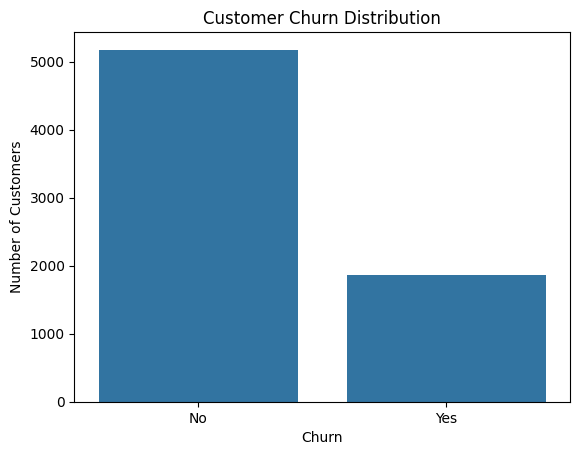

In [ ]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

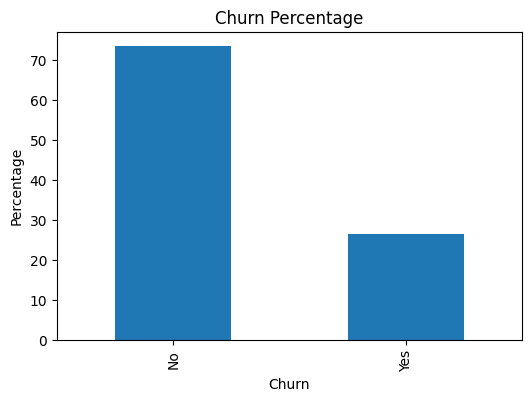

In [ ]:
(df["Churn"].value_counts(normalize=True) * 100).plot(kind="bar", figsize=(6, 4))
plt.title("Churn Percentage")
plt.ylabel("Percentage")
plt.show()

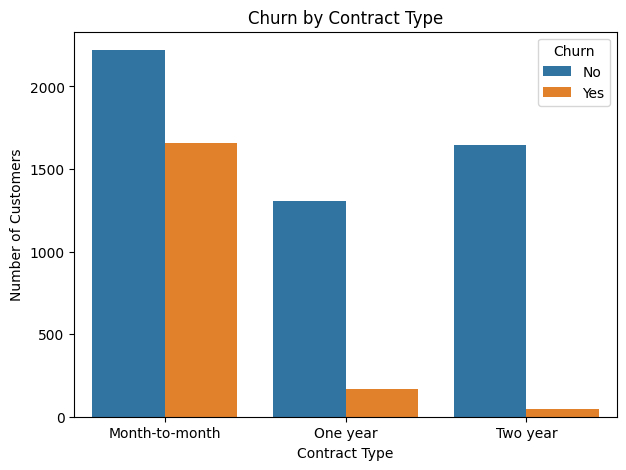

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
churn_rate = pd.crosstab( df["Contract"], df["Churn"], normalize="index") * 100
churn_rate

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


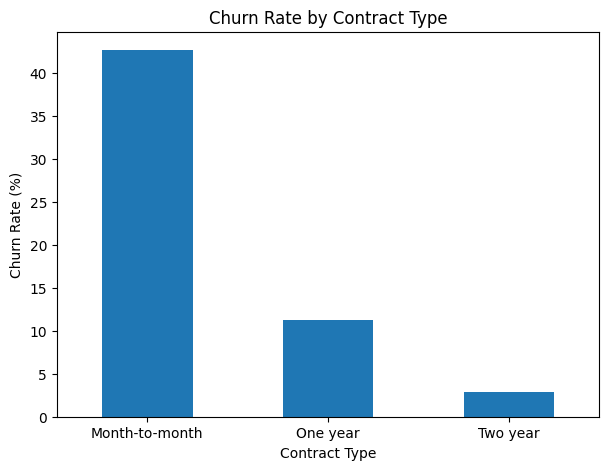

In [ ]:
churn_rate["Yes"].plot(kind="bar", figsize=(7, 5))
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract Type")
plt.xticks(rotation=0)
plt.show()

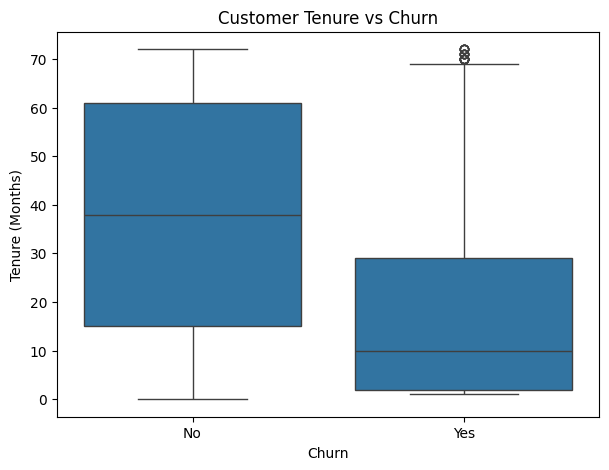

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

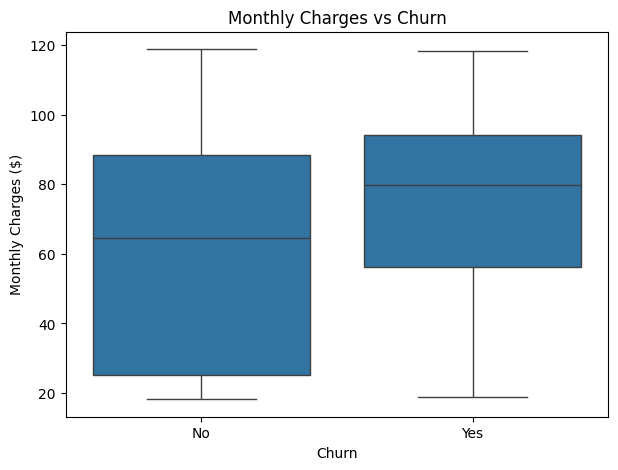

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges ($)")
plt.show()

## Exploratory Data Analysis (EDA)

### 1. Target Distribution
- The dataset contains 7,043 customers.
- Approximately 73.46% of customers did not churn, while 26.54% churned.
- The target variable is imbalanced, meaning the number of customers who stayed is significantly greater than those who left.
- Accuracy alone may not be sufficient for evaluating our models.

### 2. Contract Type vs Churn
- Month-to-month customers show substantially higher churn compared to customers on one-year and two-year contracts.
- Customers with longer-term contracts demonstrate better retention.
- Contract type appears to be an important feature for predicting churn.

### 3. Tenure vs Churn
- Customers who churn tend to have shorter tenure.
- The median tenure of customers who stayed is considerably higher than that of customers who churned.
- This suggests that newer customers may be more likely to leave.

### 4. Monthly Charges vs Churn
- Customers who churn have a higher median monthly charge compared to customers who stay.
- Monthly charges among customers who stayed show a wider distribution.
- Higher monthly charges may be associated with increased churn.

### Conclusion
The initial EDA suggests that contract type, tenure, and monthly charges may be important predictors of customer churn. These observations will be investigated further during model training and evaluation.

In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
df["TotalCharges"] = pd.to_numeric( df["TotalCharges"], errors="coerce")

In [ ]:
df["TotalCharges"].dtype

dtype('float64')

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [ ]:
df = df.dropna(subset=["TotalCharges"])
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.shape


(7032, 21)

In [ ]:
df = df.drop(["customerID"], axis=1)
X = df.drop(["Churn"], axis=1)
y = df["Churn"]
y = y.map({"Yes": 1, "No": 0})
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (7032, 19)
Target shape: (7032,)


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify= y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, train_size=0.50, random_state=42, stratify=y_temp)
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)



Train: (4922, 19) (4922,)
Validation: (1055, 19) (1055,)
Test: (1055, 19) (1055,)


In [ ]:
print("Train churn proportion:")
print(y_train.value_counts(normalize=True))

print("\nValidation churn proportion:")
print(y_val.value_counts(normalize=True))

print("\nTest churn proportion:")
print(y_test.value_counts(normalize=True))

Train churn proportion:
Churn
0    0.734254
1    0.265746
Name: proportion, dtype: float64

Validation churn proportion:
Churn
0    0.733649
1    0.266351
Name: proportion, dtype: float64

Test churn proportion:
Churn
0    0.734597
1    0.265403
Name: proportion, dtype: float64


In [ ]:
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), numerical_cols), ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (4922, 45)
Validation: (1055, 45)
Test: (1055, 45)


In [ ]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_processed, y_train)
y_val_pred = model_lr.predict(X_val_processed)
y_val_prob = model_lr.predict_proba(X_val_processed)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Accuracy: 0.8236966824644549
Precision: 0.6938775510204082
Recall: 0.604982206405694
F1 Score: 0.6463878326996197
ROC-AUC: 0.8532304339430052

Confusion Matrix:
[[699  75]
 [111 170]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       774
           1       0.69      0.60      0.65       281

    accuracy                           0.82      1055
   macro avg       0.78      0.75      0.76      1055
weighted avg       0.82      0.82      0.82      1055



### Logistic Regression - Baseline Evaluation

The Logistic Regression model achieved an accuracy of 82.37%
and a ROC-AUC score of 0.8532 on the validation dataset.

The model achieved a precision of 69.39% and recall of 60.50%
for the churn class, with an F1-score of 64.64%.

While the model demonstrates good discriminatory ability,
it misses approximately 39.5% of actual churners. This indicates
that improving churn detection (recall) may be beneficial.

Logistic Regression serves as our baseline model for comparison
with more complex models.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
model_rf.fit(X_train_processed, y_train)
y_val_pred_rf = model_rf.predict(X_val_processed)
y_val_prob_rf = model_rf.predict_proba(X_val_processed)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf))
print("Recall:", recall_score(y_val, y_val_pred_rf))
print("F1 Score:", f1_score(y_val, y_val_pred_rf))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))

Accuracy: 0.7867298578199052
Precision: 0.6359223300970874
Recall: 0.46619217081850534
F1 Score: 0.5379876796714579
ROC-AUC: 0.8198685940761584


In [ ]:
print(confusion_matrix(y_val, y_val_pred_rf))

[[699  75]
 [150 131]]


In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=42)
model_xgb.fit(X_train_processed, y_train)
y_val_pred_xgb = model_xgb.predict(X_val_processed)
y_val_prob_xgb = model_xgb.predict_proba(X_val_processed)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_xgb))
print("Precision:", precision_score(y_val, y_val_pred_xgb))
print("Recall:", recall_score(y_val, y_val_pred_xgb))
print("F1 Score:", f1_score(y_val, y_val_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

Accuracy: 0.8123222748815165
Precision: 0.6894977168949772
Recall: 0.5373665480427047
F1 Score: 0.604
ROC-AUC: 0.8472509586471352

Confusion Matrix:
[[706  68]
 [130 151]]


In [ ]:
from scipy.sparse import issparse

X_train_nn = X_train_processed.toarray() if issparse(X_train_processed) else X_train_processed
X_val_nn = X_val_processed.toarray() if issparse(X_val_processed) else X_val_processed

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model_nn = Sequential([
    Input(shape=(45,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_nn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_nn.fit(
    X_train_nn,
    y_train,
    validation_data=(X_val_nn, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.7336 - loss: 0.5071 - val_accuracy: 0.8019 - val_loss: 0.4261
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8048 - loss: 0.4231 - val_accuracy: 0.8123 - val_loss: 0.4131
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8054 - loss: 0.4159 - val_accuracy: 0.8142 - val_loss: 0.4108
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8080 - loss: 0.4128 - val_accuracy: 0.8085 - val_loss: 0.4108
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8086 - loss: 0.4101 - val_accuracy: 0.8104 - val_loss: 0.4112
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8104 - loss: 0.4079 - val_accuracy: 0.8152 - val_loss: 0.4119
Epoch 7/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8090 - loss: 0.4061 - val_accuracy: 0.8152 - val_loss: 0.4124
Epoch 8/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8092 - loss: 0.4046 - val_accuracy: 

In [ ]:
y_val_prob_nn = model_nn.predict(X_val_nn).ravel()
y_val_pred_nn = (y_val_prob_nn >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_val, y_val_pred_nn))
print("Precision:", precision_score(y_val, y_val_pred_nn))
print("Recall:", recall_score(y_val, y_val_pred_nn))
print("F1 Score:", f1_score(y_val, y_val_pred_nn))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_nn))
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_nn))

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Accuracy: 0.8085308056872038
Precision: 0.6889952153110048
Recall: 0.5124555160142349
F1 Score: 0.5877551020408164
ROC-AUC: 0.8516028028359403

Confusion Matrix:
[[709  65]
 [137 144]]


In [ ]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost", "Neural Network"],
    "Accuracy": [0.8237, 0.7867, 0.8123, 0.8085],
    "Precision": [0.6939, 0.6359, 0.6895, 0.6890],
    "Recall": [0.6050, 0.4662, 0.5374, 0.5125],
    "F1 Score": [0.6464, 0.5380, 0.6040, 0.5878],
    "ROC-AUC": [0.8532, 0.8199, 0.8473, 0.8516]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8237,0.6939,0.6050,0.6464,0.8532
1,Random Forest,0.7867,0.6359,0.4662,0.5380,0.8199
2,XGBoost,0.8123,0.6895,0.5374,0.6040,0.8473
3,Neural Network,0.8085,0.6890,0.5125,0.5878,0.8516


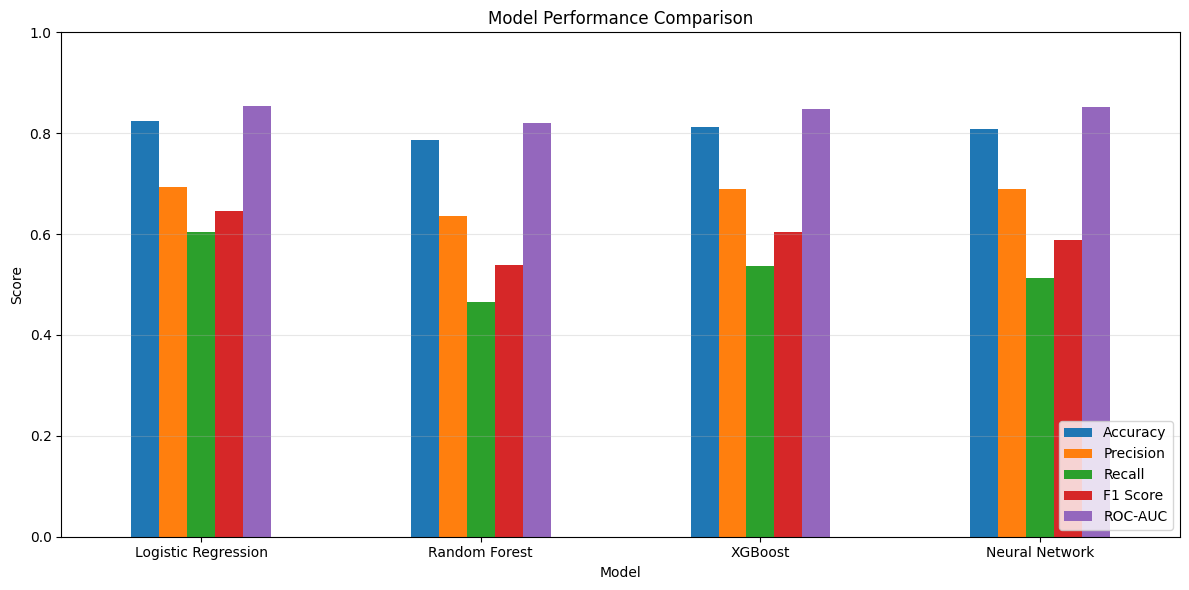

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
results.set_index("Model")[metrics].plot(kind="bar",figsize=(12, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

In [ ]:
y_test_pred = model_lr.predict(X_test_processed)
y_test_prob = model_lr.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.7886255924170616
Precision: 0.6192468619246861
Recall: 0.5285714285714286
F1 Score: 0.5703275529865125
ROC-AUC: 0.8221313364055299

Confusion Matrix:
[[684  91]
 [132 148]]


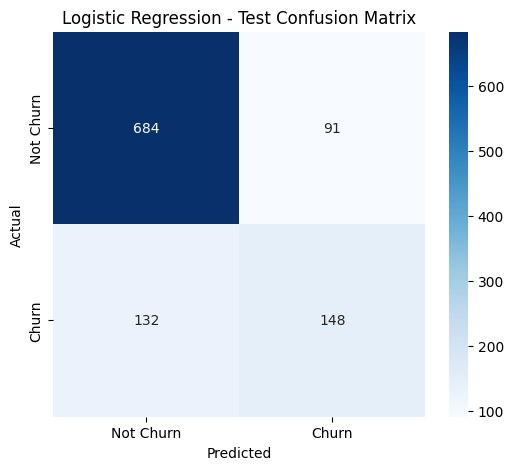

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Not Churn", "Churn"], yticklabels=["Not Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.show()

## Conclusion

In this project, I developed a machine learning pipeline to predict customer churn using the IBM Telco Customer Churn dataset.

The workflow included exploratory data analysis, data cleaning, categorical encoding, feature scaling, stratified train-validation-test splitting, and model evaluation.

Four models were evaluated:
- Logistic Regression
- Random Forest
- XGBoost
- Neural Network

Logistic Regression achieved the best overall validation performance, outperforming the more complex models in Accuracy, Precision, Recall, and F1-score. It was therefore selected for final evaluation.

### Final Test Performance

- Accuracy: 78.86%
- Precision: 61.92%
- Recall: 52.86%
- F1-score: 57.03%
- ROC-AUC: 82.21%

The results demonstrate that the model can identify customers at risk of churn, although a significant proportion of churners remain undetected. Further improvement could be explored through decision threshold optimization, class imbalance handling, and model tuning.

This project highlights the importance of comparing multiple algorithms, evaluating models using metrics beyond accuracy, and maintaining a separate test set for unbiased final evaluation.

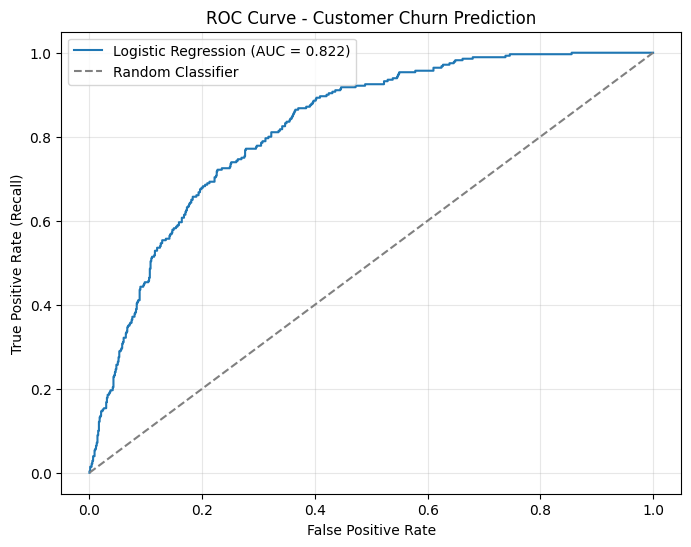

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
auc_score = roc_auc_score(y_test, y_test_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

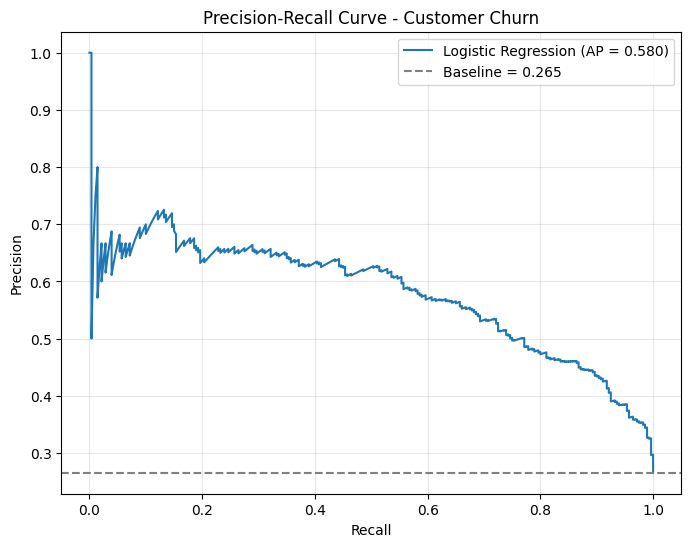

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision_curve, recall_curve, thresholds_pr = precision_recall_curve( y_test, y_test_prob)
ap_score = average_precision_score(y_test, y_test_prob)
plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, label=f"Logistic Regression (AP = {ap_score:.3f})")
baseline = y_test.mean()
plt.axhline(y=baseline, linestyle="--", color="gray", label=f"Baseline = {baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Customer Churn")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Precision-Recall Curve

The Precision-Recall curve evaluates the trade-off between precision and recall across different classification thresholds.

The model achieved an Average Precision (AP) of 0.580, compared with a baseline positive-class prevalence of 0.265.

The curve demonstrates that the model performs substantially better than the baseline at identifying churners. However, increasing recall results in a decrease in precision, highlighting the trade-off between detecting more customers at risk of churn and generating false-positive predictions.

This is particularly relevant for customer retention strategies, where the optimal classification threshold depends on the cost of missed churners versus the cost of contacting customers who are unlikely to churn.

# Final Conclusion

In this project, I developed an end-to-end machine learning pipeline to predict customer churn using the IBM Telco Customer Churn dataset. The objective was to identify customers likely to discontinue their services and understand the factors associated with churn.

The project involved exploratory data analysis, data cleaning, feature preprocessing, categorical encoding, feature scaling, stratified data splitting, model training, and evaluation.

Four machine learning models were implemented and compared:
- Logistic Regression
- Random Forest
- XGBoost
- Neural Network

Logistic Regression achieved the best overall performance on the validation set and was selected for final evaluation on the unseen test set.

### Final Test Results

| Metric | Score |
|---|---:|
| Accuracy | 78.86% |
| Precision | 61.92% |
| Recall | 52.86% |
| F1-Score | 57.03% |
| ROC-AUC | 82.21% |
| Average Precision | 58.00% |

The ROC and Precision-Recall curves demonstrated that the model performs considerably better than a random classifier in distinguishing customers likely to churn from those likely to stay.

However, the model still misses a proportion of actual churners, highlighting the potential for improvement through decision threshold optimization, class imbalance strategies, and further model tuning.

Overall, this project provided practical experience in building a complete machine learning workflow, comparing different algorithms, selecting models using appropriate evaluation metrics, and interpreting results in the context of a real-world business problem.